# 作业3：NumPy、Matplotlib 与 pandas

## 身份与环境记录

In [1]:
import hashlib
import os
import platform
import uuid

STUDENT_ID = 20244080107

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] python课程
[学号] 20244080107
[机器指纹] 025bce21d5564943
[RUN_ID] 20244080107-025bce21d5564943


本单元记录学号、当前 conda 环境、机器指纹和运行标识。机器指纹和运行标识依赖当前电脑，因此不同电脑上的结果可能不同。

## 一、围绕半圆定律

密度测试：
x=0: 0.318310
x=1: 0.275664
x=2: 0.000000
x=2.5: 0.000000

测试矩阵形状： (5, 5)
矩阵是否对称： True
特征值： [-1.50045697 -0.24398236  0.13248195  0.32957721  0.73933297]
特征值是否已排序： True

无效输入测试： n 必须是正整数。


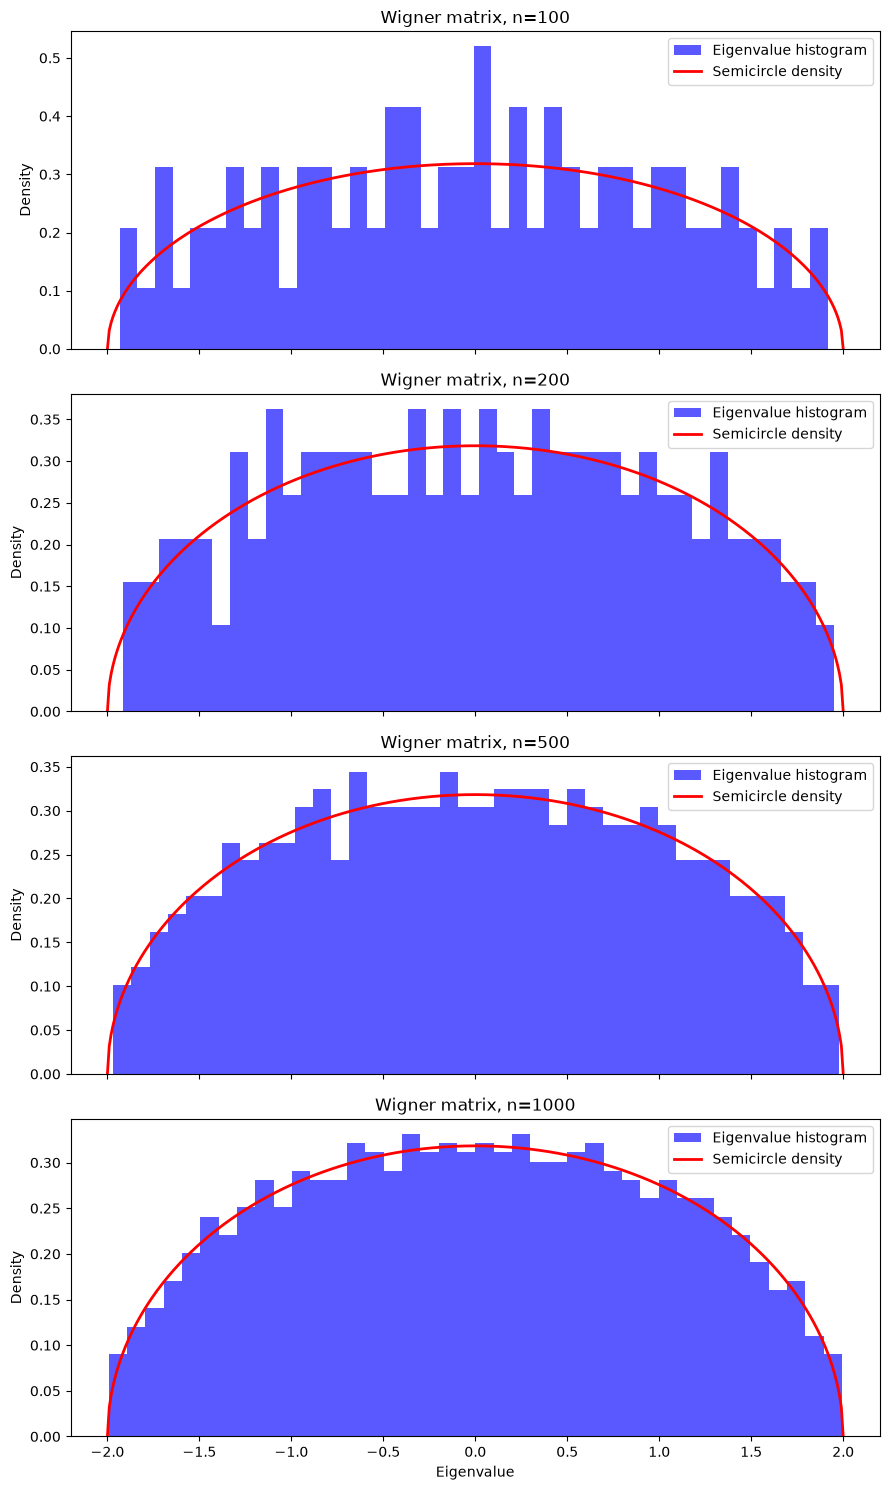

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng_wigner = np.random.default_rng(2026)


def wigner_density(x):
    """计算半圆密度在 x 处的值。"""
    if abs(x) <= 2:
        return float(np.sqrt(4 - x**2) / (2 * np.pi))
    return 0.0


def generate_wigner(n):
    """生成 n 阶实对称 Wigner 矩阵。"""
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是正整数。")
    if n <= 0:
        raise ValueError("n 必须是正整数。")

    n = int(n)
    matrix = np.zeros((n, n))
    upper_indices = np.triu_indices(n)
    values = rng_wigner.normal(
        loc=0,
        scale=np.sqrt(1 / n),
        size=len(upper_indices[0]),
    )

    matrix[upper_indices] = values
    matrix[(upper_indices[1], upper_indices[0])] = values
    return matrix


def get_spectrum(matrix):
    """返回矩阵按非递减顺序排列的特征值。"""
    return np.linalg.eigvalsh(np.asarray(matrix))


print("密度测试：")
for x in [0, 1, 2, 2.5]:
    print(f"x={x}: {wigner_density(x):.6f}")

test_matrix = generate_wigner(5)
test_spectrum = get_spectrum(test_matrix)
print("\n测试矩阵形状：", test_matrix.shape)
print("矩阵是否对称：", np.allclose(test_matrix, test_matrix.T))
print("特征值：", test_spectrum)
print("特征值是否已排序：", np.all(np.diff(test_spectrum) >= 0))

try:
    generate_wigner(0)
except (TypeError, ValueError) as error:
    print("\n无效输入测试：", error)

x_values = np.linspace(-2, 2, 400)
density_values = np.array([wigner_density(x) for x in x_values])

fig, axes = plt.subplots(4, 1, figsize=(9, 15), sharex=True)

for ax, n in zip(axes, [100, 200, 500, 1000]):
    eigenvalues = get_spectrum(generate_wigner(n))

    ax.hist(
        eigenvalues,
        bins=40,
        density=True,
        color="blue",
        alpha=0.65,
        label="Eigenvalue histogram",
    )
    ax.plot(
        x_values,
        density_values,
        color="red",
        linewidth=2,
        label="Semicircle density",
    )
    ax.set_title(f"Wigner matrix, n={n}")
    ax.set_ylabel("Density")
    ax.legend()

axes[-1].set_xlabel("Eigenvalue")
plt.tight_layout()
plt.show()

半圆密度只在 `-2 ≤ x ≤ 2` 时非零。`generate_wigner(n)` 只生成矩阵上三角的独立正态随机数，再将其复制到下三角，因此矩阵对称；每个元素的标准差为 `1/√n`，对应方差 `1/n`。`get_spectrum()` 使用适用于对称矩阵的特征值计算方法，返回从小到大排列的特征值。

图中蓝色直方图经过标准化，使面积为 1；红线表示理论半圆密度。随着矩阵阶数增加，直方图通常会更接近红线。请根据自己的图观察大约从哪个阶数开始拟合较好；一般较明显的改善会出现在 `n=500` 或 `n=1000`，但随机样本会带来一些波动。

## 二、Conway 的生命游戏

棋盘有效： True
返回值是 Python bool： True
初始棋盘：
[[0 1 0 0 0]
 [0 0 1 0 0]
 [1 1 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]

下一步棋盘：
[[0 0 0 0 0]
 [1 0 1 0 0]
 [0 1 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]

无效棋盘有效性： False

初始棋盘图：


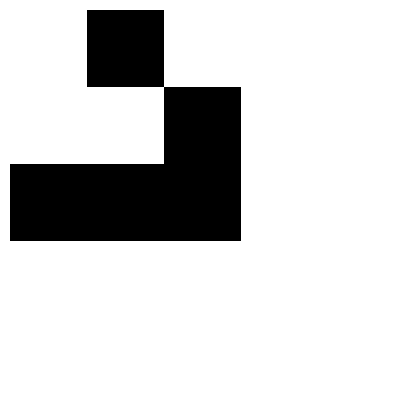

下一步棋盘图：


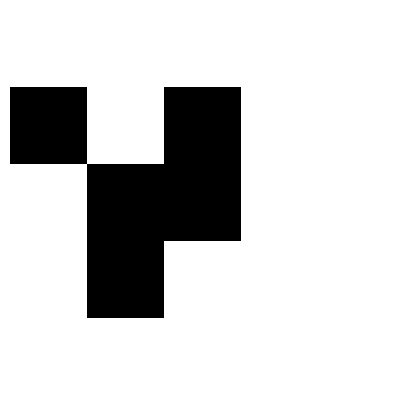

In [3]:
def is_valid_board(board):
    """判断棋盘是否为二维且只包含 0 和 1。"""
    if not isinstance(board, np.ndarray) or board.ndim != 2:
        return False
    return bool(np.isin(board, [0, 1]).all())


def gol_step(board):
    """根据生命游戏规则计算棋盘的下一步。"""
    if not is_valid_board(board):
        raise ValueError("board 必须是只包含 0 和 1 的二维 NumPy 数组。")

    neighbor_counts = np.zeros(board.shape, dtype=int)

    # np.roll 会将边缘绕回另一侧，符合环绕边界规则
    for row_shift in (-1, 0, 1):
        for col_shift in (-1, 0, 1):
            if row_shift == 0 and col_shift == 0:
                continue
            neighbor_counts += np.roll(
                np.roll(board, row_shift, axis=0),
                col_shift,
                axis=1,
            )

    next_board = (
        (neighbor_counts == 3)
        | ((board == 1) & (neighbor_counts == 2))
    )
    return next_board.astype(int)


def draw_gol_board(board):
    """将活细胞绘制为黑色，死细胞绘制为白色。"""
    if not is_valid_board(board):
        raise ValueError("board 必须是只包含 0 和 1 的二维 NumPy 数组。")

    plt.figure(figsize=(5, 5))
    plt.imshow(
        board,
        cmap=plt.get_cmap("gray_r"),
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.axis("off")
    plt.show()


board = np.array([
    [0, 1, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0],
])

print("棋盘有效：", is_valid_board(board))
print("返回值是 Python bool：", isinstance(is_valid_board(board), bool))
print("初始棋盘：")
print(board)

next_board = gol_step(board)
print("\n下一步棋盘：")
print(next_board)

print("\n无效棋盘有效性：", is_valid_board(np.array([[0, 2], [1, 0]])))

print("\n初始棋盘图：")
draw_gol_board(board)

print("下一步棋盘图：")
draw_gol_board(next_board)

## 三、使用 pandas 处理 Iris 数据

In [3]:
import pandas as pd

csv_path = "Iris.csv"
iris = pd.read_csv(csv_path)

# 统一列名大小写和空格形式，方便后续引用
iris.columns = (
    iris.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print("数据点数量：", len(iris))
print("\n列名：", iris.columns.tolist())
print("\n每列的数据类型：")
print(iris.dtypes)
print("\n花卉种类数量：", iris["species"].nunique())
print("花卉种类：", sorted(iris["species"].unique()))

# 修正第 35 行和第 38 行（默认索引分别为 34 和 37）
columns_to_correct = ["sepallengthcm", "sepalwidthcm", "petallengthcm", "petalwidthcm", "species"]
iris.loc[34, columns_to_correct] = [4.9, 3.1, 1.5, 0.2, "Iris-setosa"]
iris.loc[37, columns_to_correct] = [4.9, 3.6, 1.4, 0.1, "Iris-setosa"]

print("\n修正后的第 35、38 行：")
print(iris.loc[[34, 37]])

# 添加花瓣与萼片比例
iris["Petal.Ratio"] = iris["petallengthcm"] / iris["petalwidthcm"]
iris["Sepal.Ratio"] = iris["sepallengthcm"] / iris["sepalwidthcm"]

# 保存修正、扩展后的数据表
iris.to_csv("iris_corrected.csv", index=False)
print("\n已保存 iris_corrected.csv")

# 按花卉种类一次计算两种比例的统计量
ratio_summary = iris.groupby("species")[
    ["Petal.Ratio", "Sepal.Ratio"]
].agg(["mean", "median", "min", "max", "std"])

print("\n各花卉种类的比例统计：")
print(ratio_summary)

数据点数量： 150

列名： ['id', 'sepallengthcm', 'sepalwidthcm', 'petallengthcm', 'petalwidthcm', 'species']

每列的数据类型：
id                 int64
sepallengthcm    float64
sepalwidthcm     float64
petallengthcm    float64
petalwidthcm     float64
species              str
dtype: object

花卉种类数量： 3
花卉种类： ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']

修正后的第 35、38 行：
    id  sepallengthcm  sepalwidthcm  petallengthcm  petalwidthcm      species
34  35            4.9           3.1            1.5           0.2  Iris-setosa
37  38            4.9           3.6            1.4           0.1  Iris-setosa

已保存 iris_corrected.csv

各花卉种类的比例统计：
                Petal.Ratio                                     Sepal.Ratio  \
                       mean    median       min   max       std        mean   
species                                                                       
Iris-setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
Iris-versicolor    3.242837  3.240385  2.666667   4.1